# 고객 세분화 & LTV

In [1]:
!pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   --------------------------------- ------ 7.9/9.3 MB 40.7 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 25.3 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 28.5 MB/s  0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------  7.1/7.2 MB 33.6 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 24.8 MB/s  0:00:00

   ---------------------------------------- 0/7 [pyparsing]
   ---------------------------------------- 0/7 [pyparsing]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- --

In [2]:
!pip install seaborn

In [3]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] ='Malgun Gothic'
plt.rcParams['axes.unicode_minus'] =False

conn = sqlite3.connect('../ecommerce.db')
os.makedirs('../output', exist_ok=True)

def query(sql):
    return pd.read_sql(sql, conn)

START_DATE = '2017-01-01'
END_DATE   = '2018-08-31'
SNAPSHOT_DATE = '2018-09-01'  # RFM 기준일 (마지막 날 다음날 = "오늘"로 설정)

## 1. RFM 지표 계산
- R (Recency)   : 마지막 구매가 얼마나 최근인가? → 낮을수록 좋음
- F (Frequency) : 얼마나 자주 샀는가?           → 높을수록 좋음
- M (Monetary)  : 얼마나 많이 썼는가?           → 높을수록 좋음

In [4]:
rfm_raw = query(f"""
    SELECT
        c.customer_unique_id,
        COUNT(DISTINCT o.order_id)                                   AS frequency,
        ROUND(SUM(p.payment_value), 2)                               AS monetary,
        CAST(
            julianday('{SNAPSHOT_DATE}') 
            - julianday(MAX(o.order_purchase_timestamp)) AS INTEGER) AS recency
    FROM orders o
    JOIN payments p USING (order_id)
    JOIN customers c USING (customer_id)
    WHERE o.order_status = 'delivered'
      AND o.order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
    GROUP BY c.customer_unique_id
""")

print(f"총 고객 수: {len(rfm_raw):,}명")
display(rfm_raw.head())
print(rfm_raw.describe().round(2))

총 고객 수: 93,104명


,customer_unique_id,frequency,monetary,recency
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,113
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,116
2,0000f46a3911fa3c0805444483337064,1,86.22,539
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,323
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,290


       frequency  monetary   recency
count   93104.00  93104.00  93104.00
mean        1.03    165.15    238.24
std         0.21    226.38    150.95
min         1.00      9.59      2.00
25%         1.00     63.04    116.00
50%         1.00    107.78    220.00
75%         1.00    182.50    347.00
max        15.00  13664.08    603.00


- frequency: 매우 낮은 재구매율, 고객 대다수가 딱 1번만 구매
- monetary: 고액 이상치 존재(EDA에서 확인 한 것)
- recency: 고객 절반이 이미 이탈 위험 -> 중앙값이 220일. 절반의 고객이 마지막 구매 후 7개월 이상 지남  
=> 한 번 사고 돌아오지 않는 고객이 대부분  

[RFM 기초 분석 결론]
- 전체 고객 93,104명 중 대부분이 1회 구매 (frequency 평균 1.03)
- 중앙값 기준 220일 미구매 → 재구매 유도 전략 필요
- monetary 최대 13,664 BRL → 이상치 존재, 평균보다 중앙값 기준 해석 권장

## 2. RFM 점수화

In [5]:
# qcut: 데이터를 동일한 개수로 나눠서 구간 만들기
# R: 낮을수록 좋으니까 역순으로 점수
rfm_raw['R_score'] = pd.qcut(rfm_raw['recency'],
                             q = 5, labels = [5, 4, 3, 2, 1])

# F, M: 높을수록 좋으니까 순서대로 점수
# rank(method='first'): rank로 순위화 후 qcut → frequency=1 중복 문제 해결
rfm_raw['F_score'] = pd.qcut(rfm_raw['frequency'].rank(method='first'),
                             q = 5, labels = [1, 2, 3, 4, 5])
rfm_raw['M_score'] = pd.qcut(rfm_raw['monetary'],
                             q = 5, labels = [1, 2, 3, 4, 5])

# RFM 합산 점수
rfm_raw['RFM_score'] = (rfm_raw['R_score'].astype(int)
                        + rfm_raw['F_score'].astype(int)
                        + rfm_raw['M_score'].astype(int))
display(rfm_raw.head())

,customer_unique_id,frequency,monetary,recency,R_score,F_score,M_score,RFM_score
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,113,4,1,4,9
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,116,4,1,1,6
2,0000f46a3911fa3c0805444483337064,1,86.22,539,1,1,2,4
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,323,2,1,1,4
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,290,2,1,4,7


고객 0번: R=4, F=1, M=4, 합계=9
→ 최근에 샀고(R=4) 금액도 높은데(M=4) 한 번만 삼(F=1)
→ "최근 고액 첫 구매 고객" → 재구매 유도하면 VIP 될 가능성

고객 1번: R=4, F=1, M=1, 합계=6
→ 최근에 샀는데 금액이 낮고 한 번만 삼
→ "최근 소액 첫 구매 고객" → 아직 관계 형성 초기

고객 2번: R=1, F=1, M=2, 합계=4
→ 오래 전에 한 번 사고 안 돌아옴
→ "이탈 고객" → 거의 회복 불가

고객 3번: R=2, F=1, M=1, 합계=4
→ 꽤 오래 전에 소액 한 번
→ "이탈 위험 저가 고객"

고객 4번: R=2, F=1, M=4, 합계=7
→ 좀 된 고객인데 금액은 높았음
→ "고액이었지만 재방문 안 한 고객" → 윈백 대상  

[인사이트]
- frequency가 대부분 1이라 F_score 변별력이 낮음
- 이 데이터에서 고객 등급은 사실상 R(최근성) + M(금액)으로 결정됨
→ Retention 전략의 중요성

## 3. 고객 등급 분류

In [6]:
def classify_customer(row):
    r = int(row['R_score'])
    f = int(row['F_score'])
    m = int(row['M_score'])

    if r >= 4 and f >= 4:
        return 'Champions'          # 최근에 자주 많이 산 VIP
    elif r >= 3 and f >= 3:
        return 'Loyal Customers'    # 꾸준한 단골
    elif r >= 4 and f <= 2:
        return 'New Customers'      # 최근 첫 구매 고객
    elif r <= 2 and f >= 3:
        return 'At Risk'            # 예전엔 자주 샀는데 요즘 안 옴
    elif r <= 2 and f <= 2:
        return 'Lost'               # 오래 전에 한두 번만 산 고객
    else:
        return 'Potential Loyalists' # 성장 가능성 있는 고객

rfm_raw['segment'] = rfm_raw.apply(classify_customer, axis=1)

# 등급별 고객 수 & 비율
segment_summary = rfm_raw.groupby('segment').agg(
    고객수=('customer_unique_id', 'count'),
    평균_Recency=('recency', 'mean'),
    평균_Frequency=('frequency', 'mean'),
    평균_Monetary=('monetary', 'mean'),
    평균_RFM점수=('RFM_score', 'mean')
).round(2)

segment_summary['비율(%)'] = (
    segment_summary['고객수'] / len(rfm_raw) * 100
).round(1)

display(segment_summary.sort_values('평균_RFM점수', ascending=False))

,고객수,평균_Recency,평균_Frequency,평균_Monetary,평균_RFM점수,비율(%)
segment,,,,,,
Champions,14905,91.43,1.09,176.89,12.11,16.0
Loyal Customers,18769,169.81,1.03,161.26,10.19,20.2
New Customers,14956,92.25,1.00,163.37,9.00,16.1
At Risk,22188,393.57,1.05,167.06,8.49,23.8
Potential Loyalists,7339,221.19,1.00,154.28,7.44,7.9
Lost,14947,394.44,1.00,162.60,5.95,16.1


[고객 세분화 결론]
- At Risk + Lost = 전체의 39.9% → 재구매 유도 전략 시급
- Champions와 Lost의 Monetary 차이 14 BRL → Recency가 핵심 변수
- New Customers(16.1%)를 Loyal로 전환하는 온보딩 전략 필요
- frequency 전반적으로 낮음 → 이 플랫폼의 구조적 재구매율 한계

## 4. 시각화

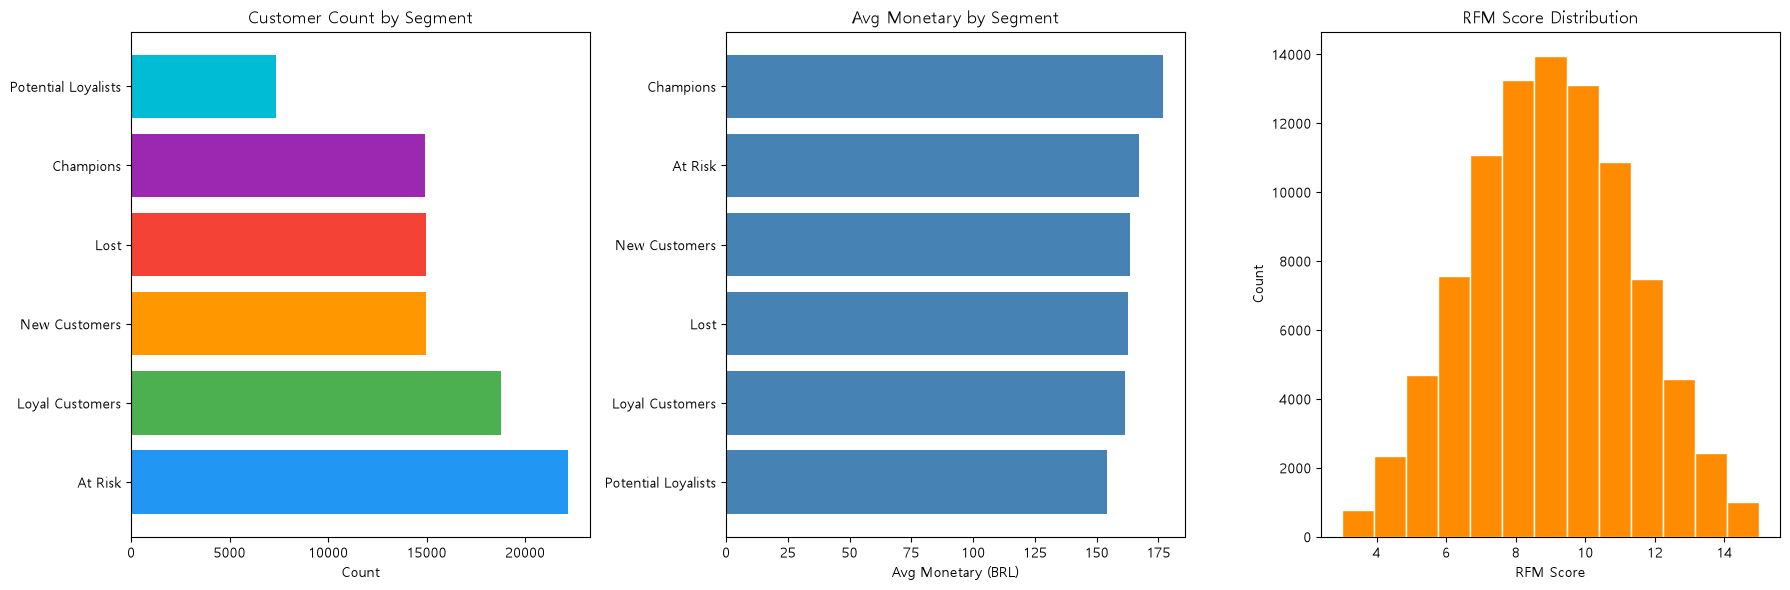

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. 등급별 고객 수
seg_count = rfm_raw['segment'].value_counts()
colors = ['#2196F3', '#4CAF50', '#FF9800', '#F44336', '#9C27B0', '#00BCD4']
axes[0].barh(seg_count.index, seg_count.values, color=colors)
axes[0].set_title('Customer Count by Segment')
axes[0].set_xlabel('Count')

# 2. 등급별 평균 매출
seg_monetary = rfm_raw.groupby('segment')['monetary'].mean().sort_values()
axes[1].barh(seg_monetary.index, seg_monetary.values, color='steelblue')
axes[1].set_title('Avg Monetary by Segment')
axes[1].set_xlabel('Avg Monetary (BRL)')
axes[1].xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x:.0f}'))

# 3. RFM 점수 분포
# bins=13: RFM 점수가 3~15점이라 총 13가지 값이 가능하니까 13으로 설정
# edgecolor='white': 막대 사이에 흰 경계선을 그어서 구분을 명확하게 해 줌
axes[2].hist(rfm_raw['RFM_score'], bins=13,
             color='darkorange', edgecolor='white')
axes[2].set_title('RFM Score Distribution')
axes[2].set_xlabel('RFM Score')
axes[2].set_ylabel('Count')

plt.tight_layout() # 서브플롯 3개가 겹치거나 잘리지 않도록 간격 자동 조정(여러 그래프 한 번에 그릴 때 써주기!!)
plt.savefig('../output/rfm_segments.png', dpi=150)
plt.show()

- **첫 번째 — 등급별 고객 수**
    
    At Risk가 압도적으로 많고 Potential Loyalists가 가장 적음.
    
- **두 번째 — 등급별 평균 매출**
    
    **여기가 핵심.** 막대 길이가 다 비슷함.
    
    ```
    Champions       176 BRL
    At Risk         167 BRL
    New Customers   163 BRL
    Lost            162 BRL  ← Champions랑 고작 14 BRL 차이
    Loyal Customers 161 BRL
    Potential       154 BRL
    ```
    
    등급이 달라도 평균 지출이 거의 똑같음. **이 데이터에서 고객 등급을 가르는 건 금액이 아니라 Recency** 라는 게 그래프로도 보임.
    
- **세 번째 — RFM 점수 분포**
    
    **정규분포에 가까운 모양**
    
    ```
    최빈값: 8~9점 구간
    3점(최저): 약 600명   ← 극소수
    15점(최고): 약 1,000명 ← 극소수
    ```
    
    대부분 고객이 중간 점수에 몰려있음. 극단적인 VIP나 극단적인 이탈 고객은 소수라는 뜻

## 5. LTV 계산
- LTV(Life Time Value): 고객 한 명이 전체 기간 동안 가져다주는 가치

[LTV 분석 방법 비교]
- 방법 1 (ARPU 기반)
    - 공식: ARPU × 평균 생애기간(20개월)
    - 장점: 직관적, 비즈니스 전체 관점
    - 단점: 고객 간 차이 미반영

- 방법 2 (개인화)
    - 공식: 평균주문금액 × (365 / recency)
    - 장점: 고객별 차이 반영, RFM 세분화와 연결
    - 단점: recency 단일 지표로 미래 추정, 단순화 한계  

→ 두 방법을 상호보완적으로 활용  
→ 방법 1로 전체 규모 파악, 방법 2로 타겟 고객 선정

1. ARPU 기반 LTV

In [8]:
# ARPU
total_revenue = query(f"""
    SELECT SUM(p.payment_value) AS total_revenue
    FROM orders o
    JOIN payments p USING (order_id)
    WHERE o.order_status = 'delivered'
      AND o.order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
""")['total_revenue'][0]          # 숫자만 가져오기

total_customers = len(rfm_raw)
ARPU = total_revenue / total_customers

In [9]:
# RPR
repeat_customers = len(rfm_raw[rfm_raw['frequency'] >= 2])
RPR = repeat_customers / total_customers

In [10]:
# LTV
avg_lifespan_months = 20 # 분석 기간 17-01 ~ 18-08
LTV_method1 = ARPU * avg_lifespan_months

print(f"총 매출액  : {total_revenue:,.0f} BRL")
print(f"총 고객 수 : {total_customers:,}명")
print(f"ARPU      : {ARPU:.2f} BRL")
print(f"RPR       : {RPR*100:.1f}% ({repeat_customers:,}명 재구매)")
print(f"LTV       : {LTV_method1:.2f} BRL  (ARPU × {avg_lifespan_months}개월)")

총 매출액  : 15,375,875 BRL
총 고객 수 : 93,104명
ARPU      : 165.15 BRL
RPR       : 3.0% (2,789명 재구매)
LTV       : 3302.95 BRL  (ARPU × 20개월)


2. 개인화 LTV(고객별 관점)
- 재구매 데이터가 부족해 고객 유지 기간을 직접 계산하기 어려움
- recency 기반으로 구매 주기를 역산하여 연간 구매 빈도를 추정

📊 등급별 평균 LTV
segment
New Customers          1189.99
Champions              1189.40
Loyal Customers         638.70
Potential Loyalists     257.75
Lost                    158.60
At Risk                 156.23
Name: LTV_method2, dtype: float64


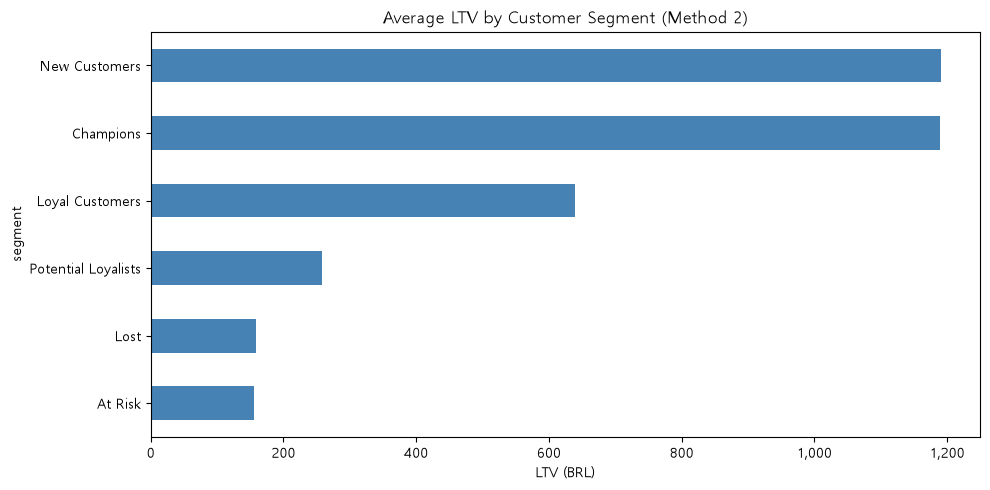

In [11]:
# 평균 주문금액
rfm_raw['avg_order_value'] = rfm_raw['monetary'] / rfm_raw['frequency']

# 연간 구매 빈도 추정 (365 / recency)
rfm_raw['annual_frequency'] = 365 / rfm_raw['recency'].clip(lower=1)

# 개인화 LTV
rfm_raw['LTV_method2'] = rfm_raw['avg_order_value'] * rfm_raw['annual_frequency']

# 등급별 평균 LTV
ltv_by_segment = rfm_raw.groupby('segment')['LTV_method2']\
                        .mean().round(2)\
                        .sort_values(ascending=False)
print("📊 등급별 평균 LTV")
print(ltv_by_segment)

# 시각화
fig, ax = plt.subplots(figsize=(10, 5))
ltv_by_segment.sort_values().plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Average LTV by Customer Segment (Method 2)')
ax.set_xlabel('LTV (BRL)')
ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.savefig('../output/ltv_by_segment.png', dpi=150)
plt.show()

- 두 방법 비교

In [12]:
print("=" * 40)
print("📊 LTV 두 가지 방법 비교")
print("=" * 40)
print(f"방법 1 (ARPU 기반)")
print(f"  ARPU : {ARPU:.2f} BRL")
print(f"  LTV  : {LTV_method1:.2f} BRL")
print(f"  RPR  : {RPR*100:.1f}%")
print()
print(f"방법 2 (개인화)")
print(f"  평균 LTV : {rfm_raw['LTV_method2'].mean():.2f} BRL")
print(f"  중앙값   : {rfm_raw['LTV_method2'].median():.2f} BRL")
print(f"  최고 등급 (Champions) : {ltv_by_segment['Champions']:.2f} BRL")
print(f"  최저 등급 (Lost)      : {ltv_by_segment['Lost']:.2f} BRL")

📊 LTV 두 가지 방법 비교
방법 1 (ARPU 기반)
  ARPU : 165.15 BRL
  LTV  : 3302.95 BRL
  RPR  : 3.0%

방법 2 (개인화)
  평균 LTV : 593.33 BRL
  중앙값   : 196.57 BRL
  최고 등급 (Champions) : 1189.40 BRL
  최저 등급 (Lost)      : 158.60 BRL


[LTV 분석 결론]
- 방법 1 (ARPU 기반)
    - ARPU: 165 BRL, LTV: 3,303 BRL (× 20개월)
    - RPR 3.0% → 고객 100명 중 97명이 재구매 없음
    - 이커머스 평균 RPR(20~30%) 대비 매우 낮은 수준
    - Retention 전략이 최우선 과제임을 시사
- 방법 2 (개인화)
    - Champions vs New Customers LTV 거의 동일 (recency 기반 한계)
    - At Risk, Lost LTV 150~160 BRL로 매우 낮음
    - frequency 데이터 부족으로 등급 간 차별화가 약함  

→ 두 방법 모두 RPR이 낮다는 동일한 문제를 가리킴  
→ 코호트 분석에서 시간축으로 더 깊이 분석 예정

## 6. 이탈 고객 특성 분석
1. 이탈/위험 vs 활성 고객 비교

📊 이탈/위험 vs 활성고객 특성 비교
            churn  active
recency    393.92  135.12
frequency    1.03    1.06
monetary   165.26  168.18


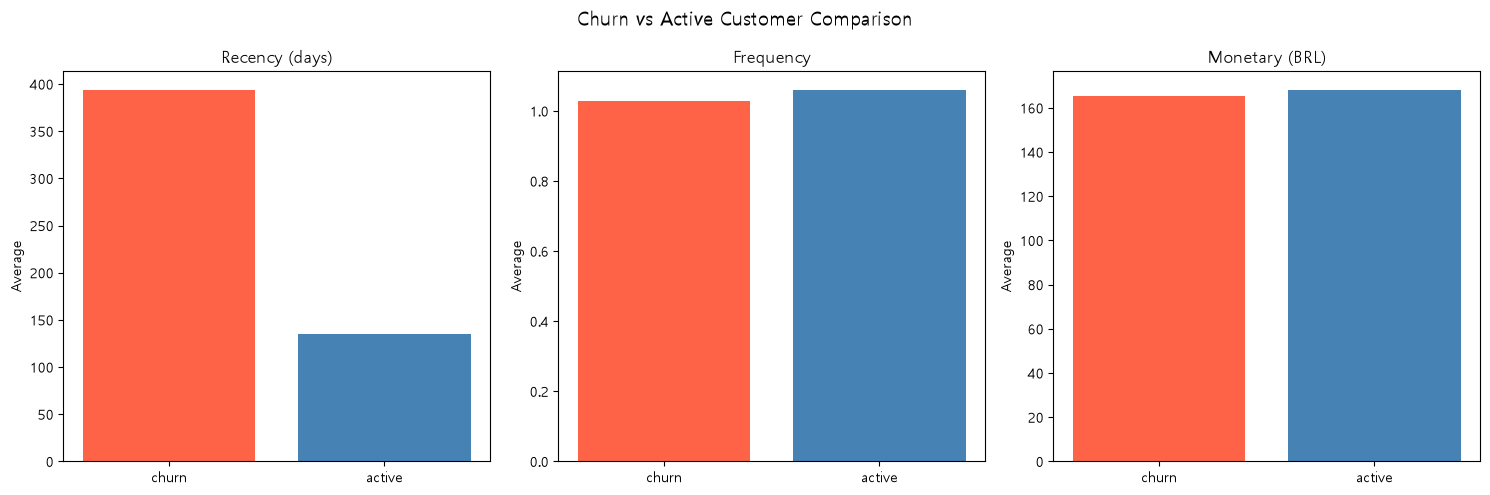

In [13]:
churn = rfm_raw[rfm_raw['segment'].isin(['Lost', 'At Risk'])].copy()
active = rfm_raw[rfm_raw['segment'].isin(['Champions', 'Loyal Customers'])].copy()

comparison = pd.DataFrame({
    'churn': churn[['recency', 'frequency', 'monetary']].mean(),
    'active'     : active[['recency', 'frequency', 'monetary']].mean()
}).round(2)

print("📊 이탈/위험 vs 활성고객 특성 비교")
print(comparison)

# 시각화
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = ['recency', 'frequency', 'monetary']
titles  = ['Recency (days)', 'Frequency', 'Monetary (BRL)']

for i, (metric, title) in enumerate(zip(metrics, titles)):
    axes[i].bar(['churn', 'active'],
                [churn[metric].mean(), active[metric].mean()],
                color=['tomato', 'steelblue'])
    axes[i].set_title(title)
    axes[i].set_ylabel('Average')

plt.suptitle('Churn vs Active Customer Comparison', fontsize=14)
plt.tight_layout()
plt.savefig('../output/churn_comparison.png', dpi=150)
plt.show()

[이탈 고객 특성 분석 결론]
- Recency: 이탈(394일) vs 활성(135일) → 3배 차이, 핵심 변수
- Frequency, Monetary: 두 그룹 간 차이 거의 없음
- 이탈을 결정하는 건 구매 금액/횟수가 아닌 재방문 여부
- 초기 구매 후 재방문을 유도하는 온보딩/리텐션 전략 필요

2. 이탈 고객 마지막 구매 카테고리

📊 이탈 고객 마지막 구매 카테고리 Top 10


,category,churn_count
0,bed_bath_table,10383
1,health_beauty,9158
2,sports_leisure,8079
3,furniture_decor,7664
4,computers_accessories,7370
5,housewares,6571
6,watches_gifts,5698
7,telephony,4289
8,garden_tools,4125
9,auto,4037


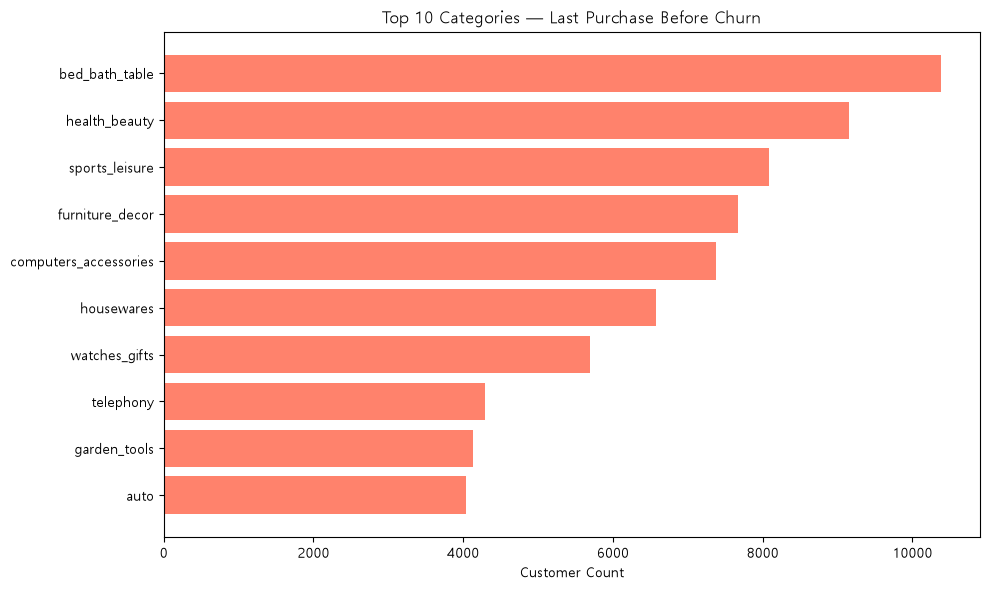

In [14]:
churn_category = query(f"""
    WITH last_order AS (
        SELECT 
            c.customer_unique_id,
            o.order_id,
            ROW_NUMBER() OVER (                          --고객별 마지막 주문만 추출
                PARTITION BY c.customer_unique_id
                ORDER BY o.order_purchase_timestamp DESC
            ) AS rn
        FROM orders o
        JOIN customers c USING (customer_id)
        WHERE o.order_status = 'delivered'
          AND o.order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
    )
    SELECT
        COALESCE(t.product_category_name_english, p.product_category_name, 'Unknown') AS category,
        COUNT(*) AS churn_count
    FROM last_order lo
    JOIN order_items oi USING (order_id)
    JOIN products     p USING (product_id)
    LEFT JOIN category_translation t
           ON p.product_category_name = t.product_category_name
    WHERE lo.rn = 1
    GROUP BY category
    ORDER BY churn_count DESC
    LIMIT 10
""")

print("📊 이탈 고객 마지막 구매 카테고리 Top 10")
display(churn_category)

# 시각화
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(churn_category['category'][::-1],
        churn_category['churn_count'][::-1],
        color='tomato', alpha=0.8)
ax.set_title('Top 10 Categories — Last Purchase Before Churn')
ax.set_xlabel('Customer Count')
plt.tight_layout()
plt.savefig('../output/churn_category.png', dpi=150)
plt.show()

[이탈 카테고리 분석 주의]
- 단순 이탈 고객 수 → 판매량 많은 카테고리가 그대로 상위권
- 올바른 해석은 카테고리별 이탈률 (이탈 고객 / 전체 고객)로 봐야 함
- 이탈률이 높은 카테고리 = 실제로 재구매가 일어나지 않는 카테고리  
-> 더 정확하게 보기 위해 카테고리별 이탈률 계산

In [15]:
# 전체 고객의 마지막 구매 카테고리 (기준 통일)
total_by_category = query(f"""
    SELECT
        c.customer_unique_id,
        COALESCE(t.product_category_name_english, p.product_category_name, 'Unknown') AS category
    FROM orders o
    JOIN customers  c  USING (customer_id)
    JOIN order_items oi USING (order_id)
    JOIN products    p  USING (product_id)
    LEFT JOIN category_translation t
           ON p.product_category_name = t.product_category_name
    WHERE o.order_status = 'delivered'
      AND o.order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
""")

last_category = (total_by_category
                 .groupby('customer_unique_id')['category']
                 .last()
                 .reset_index())

print(f"전체 고객 수: {len(last_category):,}명")
display(last_category.head())

전체 고객 수: 93,104명


,customer_unique_id,category
0,0000366f3b9a7992bf8c76cfdf3221e2,bed_bath_table
1,0000b849f77a49e4a4ce2b2a4ca5be3f,health_beauty
2,0000f46a3911fa3c0805444483337064,stationery
3,0000f6ccb0745a6a4b88665a16c9f078,telephony
4,0004aac84e0df4da2b147fca70cf8255,telephony


In [16]:
# 이탈 고객 ID 목록
churn_ids = set(churn['customer_unique_id'])

# 이탈 여부 컬럼 추가
last_category['is_churn'] = last_category['customer_unique_id'].isin(churn_ids)

# 카테고리별 집계
churn_rate = (last_category
              .groupby('category')
              .agg(
                  total_count=('customer_unique_id', 'count'),
                  churn_count=('is_churn', 'sum')
             ).reset_index())

# 이탈률 계산 & 100명 이상 필터링
# 전체 고객 규모(93,104명) 대비 0.1% 수준을 최소 표본으로 설정
churn_rate['churn_rate'] = (churn_rate['churn_count'] / churn_rate['total_count'] * 100).round(1)
churn_rate = churn_rate[churn_rate['total_count'] >= 100]

print("📊 카테고리별 이탈률")
display(churn_rate.sort_values('churn_rate', ascending=False).head(10))

📊 카테고리별 이탈률


,category,total_count,churn_count,churn_rate
31,fashion_male_clothing,100,74,74.0
32,fashion_shoes,225,148,65.8
55,market_place,259,156,60.2
48,home_confort,335,197,58.8
15,computers,176,102,58.0
34,fashion_underwear_beach,113,65,57.5
35,fixed_telephony,200,113,56.5
17,consoles_games,990,549,55.5
72,toys,3671,2021,55.1
21,cool_stuff,3461,1903,55.0


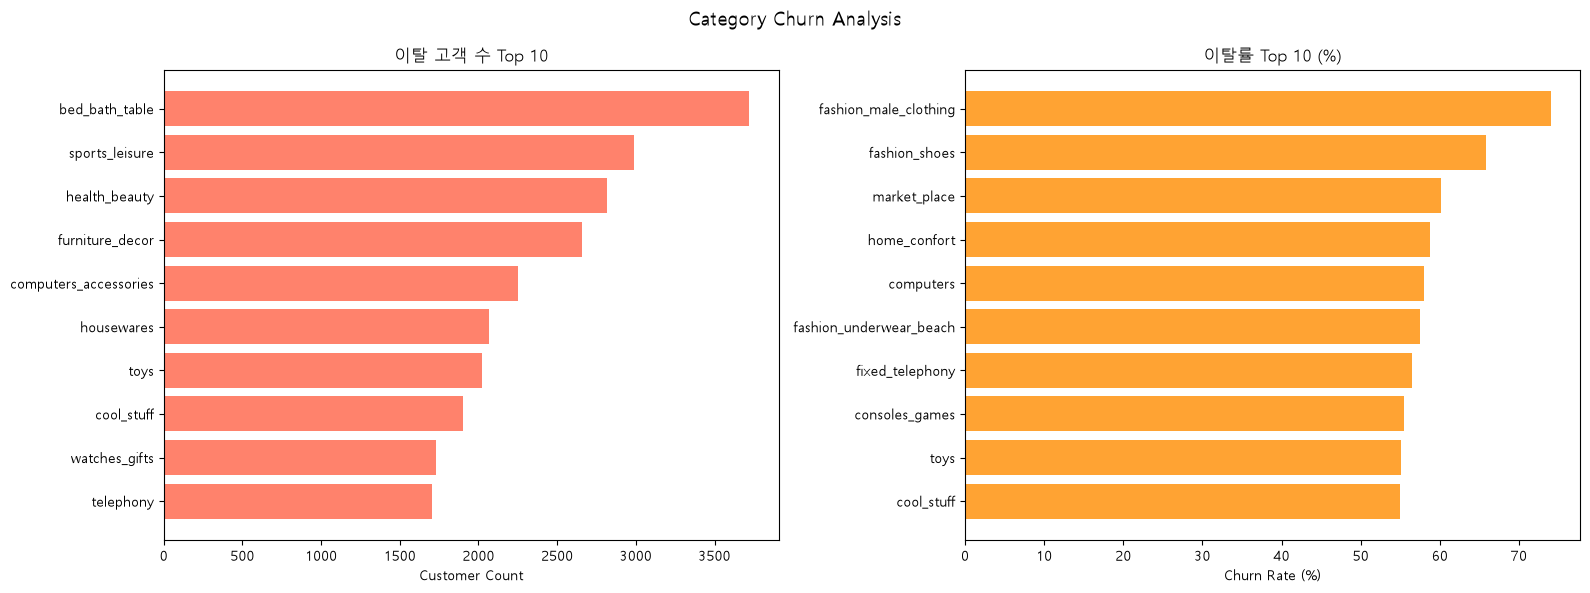

In [17]:
# 시각화
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ① 이탈 고객 수
top_count = churn_rate.sort_values('churn_count', ascending=False).head(10)
axes[0].barh(top_count['category'][::-1],
             top_count['churn_count'][::-1],
             color='tomato', alpha=0.8)
axes[0].set_title('이탈 고객 수 Top 10')
axes[0].set_xlabel('Customer Count')

# ② 이탈률
top_rate = churn_rate.sort_values('churn_rate', ascending=False).head(10)
axes[1].barh(top_rate['category'][::-1],
             top_rate['churn_rate'][::-1],
             color='darkorange', alpha=0.8)
axes[1].set_title('이탈률 Top 10 (%)')
axes[1].set_xlabel('Churn Rate (%)')

plt.suptitle('Category Churn Analysis', fontsize=14)
plt.tight_layout()
plt.savefig('../output/churn_rate_by_category.png', dpi=150)
plt.show()

[카테고리별 이탈률 분석 결론]
- 이탈 고객 수 vs 이탈률 순위가 완전히 다름  
   → 단순 이탈 고객 수는 판매량에 비례하므로 이탈률로 봐야 정확
- 패션 카테고리 이탈률 압도적 1위 (74%)  
   → 온라인 패션 특성상 사이즈/색상 불일치로 재구매 꺼림  
   → 사이즈 가이드, 무료 반품 정책 등 보완 필요
- toys, cool_stuff, consoles_games: 표본 크고 이탈률 높음  
   → 통계적으로 신뢰할 수 있는 고이탈 카테고리  
   → 구매 후 후속 마케팅(관련 상품 추천 등) 전략 필요

3. 이탈 고객 리뷰 점수 분포

In [19]:
churn.head()

,customer_unique_id,frequency,monetary,recency,R_score,F_score,M_score,RFM_score,segment,avg_order_value,annual_frequency,LTV_method2
2,0000f46a3911fa3c0805444483337064,1,86.22,539,1,1,2,4,Lost,86.22,0.677180,58.386456
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,323,2,1,1,4,Lost,43.62,1.130031,49.291950
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,290,2,1,4,7,Lost,196.89,1.258621,247.809828
8,0005e1862207bf6ccc02e4228effd9a0,1,150.12,545,1,1,4,6,Lost,150.12,0.669725,100.539083
10,0006fdc98a402fceb4eb0ee528f6a8d4,1,29.00,409,1,1,1,3,Lost,29.00,0.892421,25.880196


In [25]:
churn_ids = churn['customer_unique_id'].tolist()

churn_review = query(f"""
    SELECT
        r.review_score,
        COUNT(*) AS count,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 1) AS pct  -- 각 점수별 리뷰 수 * 100 / 전체 리뷰 수 합계
    FROM reviews r
    JOIN orders o USING (order_id)
    JOIN customers c USING (customer_id)
    WHERE c.customer_unique_id IN ({','.join([f"'{i}'" for i in churn_ids])})
    GROUP BY r.review_score
    ORDER BY r.review_score
""")

print("📊 이탈 고객 리뷰 점수")
display(churn_review)

# 전체 고객 리뷰 분포
all_review = query("""
    SELECT
        review_score,
        COUNT(*) AS count,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 1) AS pct
    FROM reviews
    GROUP BY review_score
    ORDER BY review_score
""")

print("\n 📊 전체 고객 리뷰 점수")
display(all_review)

📊 이탈 고객 리뷰 점수


,review_score,count,pct
0,1,3468,9.1
1,2,1167,3.0
2,3,3290,8.6
3,4,7746,20.2
4,5,22644,59.1



 📊 전체 고객 리뷰 점수


,review_score,count,pct
0,1,11424,11.5
1,2,3151,3.2
2,3,8179,8.2
3,4,19142,19.3
4,5,57328,57.8


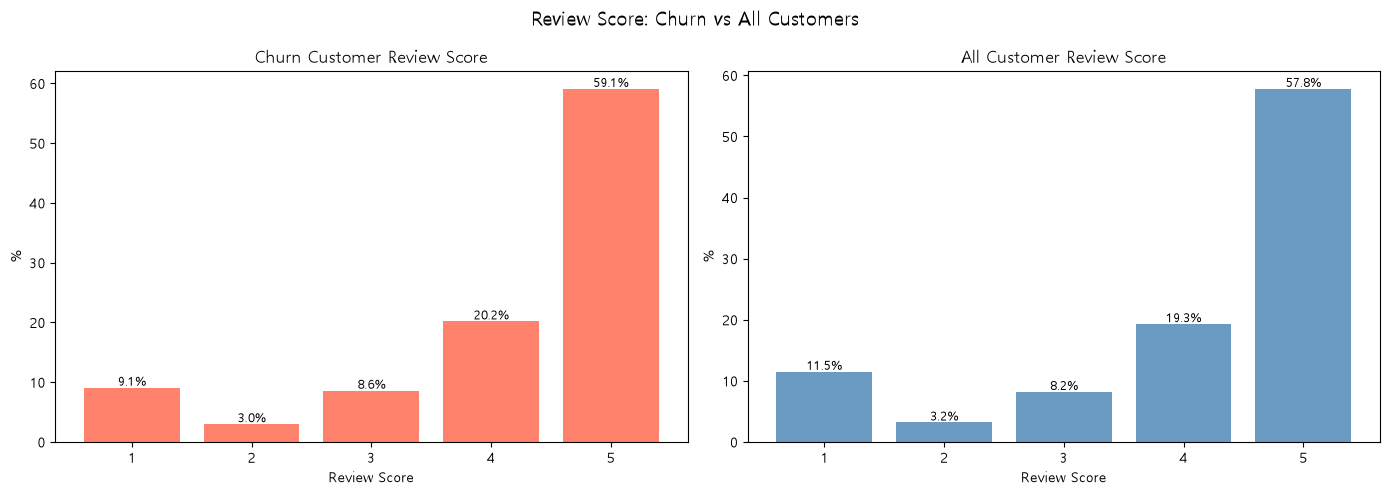

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ① 이탈 고객 리뷰 점수
axes[0].bar(churn_review['review_score'], churn_review['pct'],
            color='tomato', alpha=0.8)
axes[0].set_title('Churn Customer Review Score')
axes[0].set_xlabel('Review Score')
axes[0].set_ylabel('%')
axes[0].set_xticks([1, 2, 3, 4, 5])

# 막대 위에 % 수치 표시
for i, row in churn_review.iterrows():
    axes[0].text(row['review_score'], row['pct'] + 0.3,
                 f"{row['pct']}%", ha='center', fontsize=9)

# ② 전체 고객 리뷰 점수
axes[1].bar(all_review['review_score'], all_review['pct'],
            color='steelblue', alpha=0.8)
axes[1].set_title('All Customer Review Score')
axes[1].set_xlabel('Review Score')
axes[1].set_ylabel('%')
axes[1].set_xticks([1, 2, 3, 4, 5])

for i, row in all_review.iterrows():
    axes[1].text(row['review_score'], row['pct'] + 0.3,
                 f"{row['pct']}%", ha='center', fontsize=9)

plt.suptitle('Review Score: Churn vs All Customers', fontsize=14)
plt.tight_layout()
plt.savefig('../output/churn_review.png', dpi=150)
plt.show()

[이탈 고객 리뷰 분석 결론]
- 이탈 고객의 5점 비율(59.1%) > 전체 고객 5점 비율(57.8%)
- 이탈 고객의 1점 비율(9.1%)  < 전체 고객 1점 비율(11.5%)
- 즉, 이탈은 불만족이 아닌 재구매 동기 부재가 원인
- "좋은 경험을 했지만 돌아올 이유를 못 찾은 고객"  
→ 해결책: 불만 해소보다 재방문 동기 제공이 핵심 (리마인드 푸시, 개인화 추천, 쿠폰 등 Retention 마케팅)

4. 이탈 고객 결제 수단 분포

In [27]:
churn_payment = query(f"""
    SELECT
        p.payment_type,
        COUNT(DISTINCT o.order_id)                          AS order_count,
        ROUND(COUNT(DISTINCT o.order_id) * 100.0 
              / SUM(COUNT(DISTINCT o.order_id)) OVER (), 1) AS pct            
    FROM orders o
    JOIN payments p USING (order_id)
    JOIN customers c USING (customer_id)
    WHERE o.order_status = 'delivered'
      AND o.order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
      AND c.customer_unique_id IN ({','.join([f"'{i}'" for i in churn_ids])})
    GROUP BY p.payment_type
    ORDER BY order_count DESC
""")

print("📊 이탈 고객 결제 수단")
display(churn_payment)

# 전체 고객 리뷰 분포
all_payment = query(f"""
    SELECT
        p.payment_type,
        COUNT(DISTINCT o.order_id)                                    AS order_count,
        ROUND(COUNT(DISTINCT o.order_id) * 100.0
              / SUM(COUNT(DISTINCT o.order_id)) OVER (), 1)           AS pct
    FROM orders o
    JOIN payments p USING (order_id)
    WHERE o.order_status = 'delivered'
      AND o.order_purchase_timestamp BETWEEN '{START_DATE}' AND '{END_DATE}'
    GROUP BY p.payment_type
    ORDER BY order_count DESC
""")

print("\n 📊 전체 고객 결제 수단")
display(all_payment)

📊 이탈 고객 결제 수단


,payment_type,order_count,pct
0,credit_card,29143,74.4
1,boleto,8079,20.6
2,voucher,1621,4.1
3,debit_card,351,0.9



 📊 전체 고객 결제 수단


,payment_type,order_count,pct
0,credit_card,74095,75.3
1,boleto,19140,19.5
2,voucher,3670,3.7
3,debit_card,1483,1.5


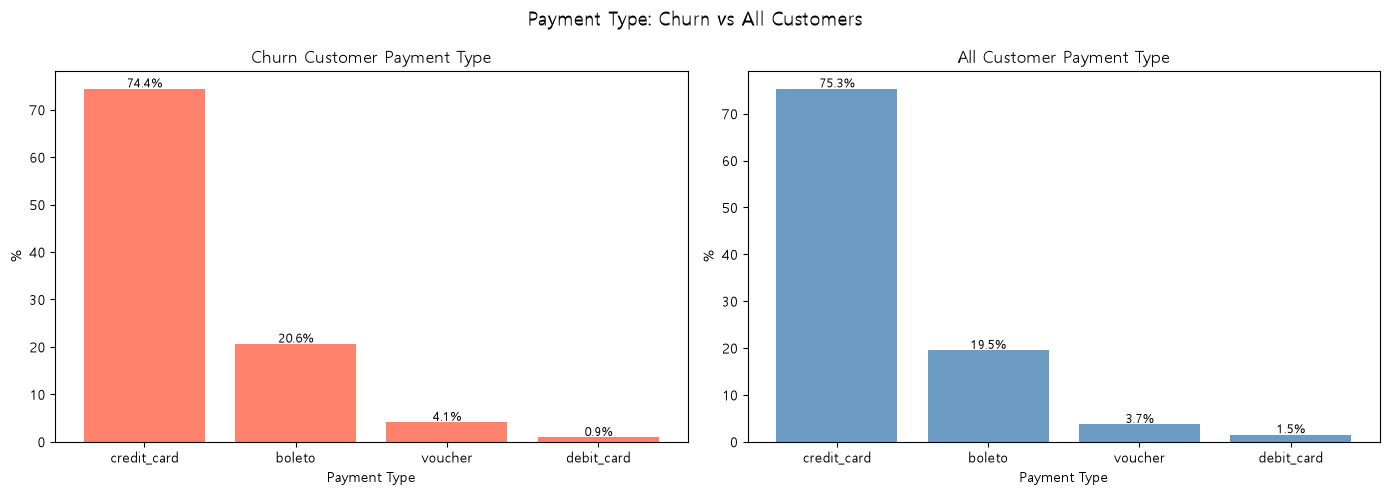

In [28]:
# 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(churn_payment['payment_type'], churn_payment['pct'],
            color='tomato', alpha=0.8)
axes[0].set_title('Churn Customer Payment Type')
axes[0].set_xlabel('Payment Type')
axes[0].set_ylabel('%')
for i, row in churn_payment.iterrows():
    axes[0].text(i, row['pct'] + 0.3,
                 f"{row['pct']}%", ha='center', fontsize=9)

axes[1].bar(all_payment['payment_type'], all_payment['pct'],
            color='steelblue', alpha=0.8)
axes[1].set_title('All Customer Payment Type')
axes[1].set_xlabel('Payment Type')
axes[1].set_ylabel('%')
for i, row in all_payment.iterrows():
    axes[1].text(i, row['pct'] + 0.3,
                 f"{row['pct']}%", ha='center', fontsize=9)

plt.suptitle('Payment Type: Churn vs All Customers', fontsize=14)
plt.tight_layout()
plt.savefig('../output/churn_payment.png', dpi=150)
plt.show()

📊 분석 2 이탈 고객 특성 종합  

지금까지 4가지를 분석했는데 결론이 일관됨.  

RFM 비교    → Recency만 차이, Frequency/Monetary 동일  
카테고리    → 패션 카테고리 이탈률 높음 (74%)  
리뷰 점수   → 이탈/전체 거의 동일 (불만족이 원인 아님)  
결제 수단   → 이탈/전체 거의 동일 (결제 수단과 무관)  

"이탈 고객은 불만족해서 떠난 게 아니라, 재구매 동기가 없어서 자연스럽게 이탈했다. 따라서 CS 개선보다 첫 구매 후 재방문을 유도하는 Retention 마케팅이 핵심 전략이다."